
Ce notebook compare les deux systèmes construits dans le projet :

| | Système 1 (Khaoula) | Système 2 (Sarah) |
|--|--|--|
| **Signal** | Note numérique `Reviewer_Score` | Texte de l'avis via DistilBERT |
| **Score** | Bayesian Average des scores 0–10 | `mean(P(Positive))` sur tous les snippets |
| **Source** | `hotel_stats_ratings.csv` | `hotel_scores.csv` |
| **Hôtels couverts** | 1 492 | 1 391 (≥50 snippets) |

### Pourquoi les résultats sont différents — hypothèse centrale

Les labels DistilBERT viennent de la **structure du formulaire Booking.com**  
(`Positive_Review` → Positive, `Negative_Review` → Negative),  
**totalement indépendants** des notes numériques.  
Un client peut donner 9.6/10 et écrire *"broken window, bio weapon in fridge, constant noise"* dans le champ négatif.  
DistilBERT prédit Negative (P=0.003) pour ce snippet. Le Système 1 compte ce séjour positivement.  
**C'est exactement la divergence que ce notebook quantifie.**


## 1. Imports

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, warnings
warnings.filterwarnings('ignore')

os.makedirs('../results', exist_ok=True)
os.makedirs('../results/visualizations', exist_ok=True)
print('Imports OK')

Imports OK


## 2. Chargement des données

Chargement robuste : si un fichier résultat est absent (notebooks 05/06 non exécutés),  
il est recalculé directement depuis les fichiers bruts.


In [2]:
PATH_RATINGS     = '../results/hotel_stats_ratings.csv'
PATH_SCORES      = '../results/hotel_scores.csv'
PATH_CLEAN       = '../data/processed/clean_reviews.csv'
PATH_PREDICTIONS = '../data/processed/hotel_reviews_with_predictions.csv'

# ── Système 1 : Ratings ───────────────────────────────────────────────────
if os.path.exists(PATH_RATINGS):
    df_ratings = pd.read_csv(PATH_RATINGS)
    print(f'[OK] hotel_stats_ratings.csv  ({len(df_ratings):,} hotels)')
else:
    print('[INFO] Recalcul hotel_stats_ratings.csv depuis clean_reviews.csv ...')
    raw = pd.read_csv(PATH_CLEAN, low_memory=False)
    raw.columns = [c.strip() for c in raw.columns]
    raw['Reviewer_Score'] = pd.to_numeric(raw['Reviewer_Score'], errors='coerce')
    raw.dropna(subset=['Hotel_Name', 'Reviewer_Score'], inplace=True)
    raw['Hotel_Name'] = raw['Hotel_Name'].str.strip()

    df_ratings = raw.groupby('Hotel_Name').agg(
        nb_avis      = ('Reviewer_Score', 'count'),
        score_moyen  = ('Reviewer_Score', 'mean'),
        score_median = ('Reviewer_Score', 'median'),
        score_std    = ('Reviewer_Score', 'std'),
    ).reset_index()
    df_ratings['score_std'] = df_ratings['score_std'].fillna(0)
    # Bayesian Average : score = (v*R + m*C) / (v+m)
    C_global = raw['Reviewer_Score'].mean()      # ancrage
    m_seuil  = df_ratings['nb_avis'].median()    # regularisation
    df_ratings['score_bayes'] = (
        (df_ratings['nb_avis'] * df_ratings['score_moyen'] + m_seuil * C_global)
        / (df_ratings['nb_avis'] + m_seuil)
    )
    df_ratings = df_ratings.sort_values('score_bayes', ascending=False).reset_index(drop=True)
    df_ratings['rang_ratings'] = df_ratings.index + 1
    df_ratings.to_csv(PATH_RATINGS, index=False)
    print(f'[OK] Recalcule et sauvegarde ({len(df_ratings):,} hotels)')

# ── Système 2 : Sentiments ────────────────────────────────────────────────
if os.path.exists(PATH_SCORES):
    df_sent = pd.read_csv(PATH_SCORES)
    print(f'[OK] hotel_scores.csv  ({len(df_sent):,} hotels)')
else:
    print('[INFO] Recalcul hotel_scores.csv depuis hotel_reviews_with_predictions.csv ...')
    pred = pd.read_csv(PATH_PREDICTIONS, low_memory=False)
    df_sent = pred.groupby('hotel').agg(
        n_snippets         = ('prob_positive', 'count'),
        sentiment_score    = ('prob_positive', 'mean'),
        mean_prob_negative = ('prob_negative', 'mean'),
        n_pred_positive    = ('distilbert_sentiment', lambda x: (x=='Positive').sum()),
        n_pred_negative    = ('distilbert_sentiment', lambda x: (x=='Negative').sum()),
        avg_score          = ('score', 'mean'),
    ).reset_index()
    df_sent['pct_pred_positive'] = df_sent['n_pred_positive'] / df_sent['n_snippets'] * 100
    df_sent = df_sent[df_sent['n_snippets'] >= 50].reset_index(drop=True)
    df_sent.sort_values('sentiment_score', ascending=False).to_csv(PATH_SCORES, index=False)
    print(f'[OK] Recalcule et sauvegarde ({len(df_sent):,} hotels avec >= 50 snippets)')

# ── Résumé colonnes ───────────────────────────────────────────────────────
print(f'\nColonnes ratings : {df_ratings.columns.tolist()}')
print(f'Colonnes sent    : {df_sent.columns.tolist()}')
print(f'\nScore bayes range  : [{df_ratings["score_bayes"].min():.3f}, {df_ratings["score_bayes"].max():.3f}]')
print(f'Sentiment range    : [{df_sent["sentiment_score"].min():.4f}, {df_sent["sentiment_score"].max():.4f}]')
print(f'  (plage bornee 0.34–0.77 attendue : structure bimodale du dataset)')

[OK] hotel_stats_ratings.csv  (1,492 hotels)
[OK] hotel_scores.csv  (1,391 hotels)

Colonnes ratings : ['Hotel_Name', 'nb_avis', 'score_moyen', 'score_median', 'score_std', 'score_min', 'score_max', 'score_bayes', 'rang_ratings', 'rang_brut', 'rang_bayes', 'diff_rang']
Colonnes sent    : ['hotel', 'n_snippets', 'sentiment_score', 'mean_prob_negative', 'n_pred_positive', 'n_pred_negative', 'avg_score', 'pct_pred_positive']

Score bayes range  : [6.798, 9.315]
Sentiment range    : [0.3432, 0.7658]
  (plage bornee 0.34–0.77 attendue : structure bimodale du dataset)


## 3. Préparation et fusion

Points importants :
- `hotel_scores.csv` utilise la colonne `hotel`, `hotel_stats_ratings.csv` utilise `Hotel_Name`
- Le système 2 couvre 1 391 hôtels (filtre ≥50 snippets), le système 1 en couvre 1 492  
  → l'inner join donne ~1 391 hôtels communs
- Le rang percentile [0,1] permet de comparer les deux classements sur la même échelle


In [3]:
# ── Normalisation colonne hotel → Hotel_Name ─────────────────────────────
if 'hotel' in df_sent.columns:
    df_sent = df_sent.rename(columns={'hotel': 'Hotel_Name'})

# ── Colonne pct_pred_positive (calcul à la volée si absente) ─────────────
if 'pct_pred_positive' not in df_sent.columns:
    if {'n_pred_positive', 'n_snippets'}.issubset(df_sent.columns):
        df_sent['pct_pred_positive'] = df_sent['n_pred_positive'] / df_sent['n_snippets'] * 100
    else:
        df_sent['pct_pred_positive'] = np.nan

# ── Rang ratings ─────────────────────────────────────────────────────────
if 'rang_ratings' not in df_ratings.columns:
    df_ratings = df_ratings.sort_values('score_bayes', ascending=False).reset_index(drop=True)
    df_ratings['rang_ratings'] = df_ratings.index + 1

n_r = len(df_ratings)
df_ratings['rang_pct_ratings'] = (df_ratings['rang_ratings'] - 1) / max(n_r - 1, 1)

# ── Rang sentiments ───────────────────────────────────────────────────────
df_sent = df_sent.sort_values('sentiment_score', ascending=False).reset_index(drop=True)
df_sent['rang_sentiments'] = df_sent.index + 1
n_s = len(df_sent)
df_sent['rang_pct_sentiments'] = (df_sent['rang_sentiments'] - 1) / max(n_s - 1, 1)

# ── Inner join ────────────────────────────────────────────────────────────
cols_r = ['Hotel_Name', 'rang_ratings', 'rang_pct_ratings', 'score_bayes', 'nb_avis']
cols_s = [c for c in ['Hotel_Name', 'rang_sentiments', 'rang_pct_sentiments',
                       'sentiment_score', 'n_snippets', 'pct_pred_positive',
                       'avg_score'] if c in df_sent.columns]

comparaison = df_ratings[cols_r].merge(df_sent[cols_s], on='Hotel_Name', how='inner')

# ── Divergences ───────────────────────────────────────────────────────────
comparaison['diff_rang_pct'] = (
    comparaison['rang_pct_ratings'] - comparaison['rang_pct_sentiments']
).abs()
comparaison['diff_rang_abs'] = (
    comparaison['rang_ratings'] - comparaison['rang_sentiments']
).abs()
# Sens de la divergence : positif = bien note mais mal senti
comparaison['sens_divergence'] = (
    comparaison['rang_pct_ratings'] - comparaison['rang_pct_sentiments']
)

print(f'Hotels en commun (inner join) : {len(comparaison):,}')
print(f'  Ratings uniquement (non couverts par sentiment) : {n_r - len(comparaison)}')
print('\nApercu :')
print(comparaison[['Hotel_Name','rang_ratings','rang_sentiments',
                    'score_bayes','sentiment_score','diff_rang_pct']]
      .head(10).round(4).to_string(index=False))

Hotels en commun (inner join) : 1,391
  Ratings uniquement (non couverts par sentiment) : 101

Apercu :
                          Hotel_Name  rang_ratings  rang_sentiments  score_bayes  sentiment_score  diff_rang_pct
      Intercontinental London The O2             1              365       9.3152           0.6058         0.2619
            Amba Hotel Charing Cross             2              127       9.1517           0.6530         0.0900
Shangri La Hotel at The Shard London             3              433       9.1367           0.5969         0.3094
                         Hotel Berna             4               20       9.1364           0.7110         0.0117
                  Olivia Plaza Hotel             5               70       9.1305           0.6742         0.0470
                   Hotel Casa Camper             6                3       9.1156           0.7499         0.0019
                      Hotel Esther a             7              214       9.1124           0.6307        

## 4. Top 10 de chaque système

In [4]:
top10_r = (comparaison.nsmallest(10, 'rang_ratings')
           [['Hotel_Name','rang_ratings','score_bayes',
             'rang_sentiments','sentiment_score','diff_rang_pct']]
           .reset_index(drop=True))
top10_r.index += 1

top10_s = (comparaison.nsmallest(10, 'rang_sentiments')
           [['Hotel_Name','rang_sentiments','sentiment_score',
             'rang_ratings','score_bayes','diff_rang_pct']]
           .reset_index(drop=True))
top10_s.index += 1

print('=== TOP 10 — Systeme RATINGS (Bayesian Average) ===')
print(top10_r.round(4).to_string())

print('\n=== TOP 10 — Systeme SENTIMENTS (DistilBERT mean P(Positive)) ===')
print(top10_s.round(4).to_string())

communs = set(top10_r['Hotel_Name']) & set(top10_s['Hotel_Name'])
print(f'\nHotels dans les deux Top 10 : {len(communs)}')
for h in sorted(communs): print(f'  [OK] {h}')

=== TOP 10 — Systeme RATINGS (Bayesian Average) ===
                              Hotel_Name  rang_ratings  score_bayes  rang_sentiments  sentiment_score  diff_rang_pct
1         Intercontinental London The O2             1       9.3152              365           0.6058         0.2619
2               Amba Hotel Charing Cross             2       9.1517              127           0.6530         0.0900
3   Shangri La Hotel at The Shard London             3       9.1367              433           0.5969         0.3094
4                            Hotel Berna             4       9.1364               20           0.7110         0.0117
5                     Olivia Plaza Hotel             5       9.1305               70           0.6742         0.0470
6                      Hotel Casa Camper             6       9.1156                3           0.7499         0.0019
7                         Hotel Esther a             7       9.1124              214           0.6307         0.1492
8           

## 5. Corrélation de Spearman

Mesure si les deux classements ordonnent les hôtels de la même façon.  
Rappel : DistilBERT est entraîné sur des labels **indépendants** des notes → une corrélation  
modérée (pas trop haute, pas trop basse) est le résultat attendu et souhaité.


In [5]:
corr, pval = stats.spearmanr(
    comparaison['rang_ratings'],
    comparaison['rang_sentiments']
)

print('=== Correlation de Spearman entre les deux classements ===')
print(f'  rho   = {corr:.4f}')
print(f'  p-val = {pval:.6f}')

if corr >= 0.8:
    interp = ('Forte correlation : les deux systemes convergent.\n'
              '  Le texte confirme les notes — sentiments peu differents des ratings.')
elif corr >= 0.5:
    interp = ('Correlation moderee : les deux signaux sont complementaires.\n'
              '  Le texte apporte une information que la note seule ne capture pas.\n'
              '  => Justifie la construction des deux systemes separement.')
else:
    interp = ('Faible correlation : divergences importantes.\n'
              '  Le texte est nettement plus informatif que la note numerique.')
print(f'\n  => {interp}')

print('\n=== Statistiques de divergence (echelle percentile 0-1) ===')
print(f"  Divergence moyenne   : {comparaison['diff_rang_pct'].mean():.3f}")
print(f"  Divergence mediane   : {comparaison['diff_rang_pct'].median():.3f}")
print(f"  Divergence max       : {comparaison['diff_rang_pct'].max():.3f}")
print(f"  Hotels ecart > 10%   : {(comparaison['diff_rang_pct'] > 0.10).sum()}")
print(f"  Hotels ecart > 25%   : {(comparaison['diff_rang_pct'] > 0.25).sum()}")

# sens_divergence = rang_pct_ratings - rang_pct_sentiments
# rang_pct = 0 → meilleur rang / rang_pct = 1 → pire rang
# positif → rang_pct_ratings > rang_pct_sentiments
#          → hotel mal classe en ratings, bien classe en sentiment
#          → BIEN SENTI mais MAL NOTE  (Sentiment > Rating)
# negatif → hotel bien classe en ratings, mal classe en sentiment
#          → BIEN NOTE  mais MAL SENTI  (Rating > Sentiment)
sent_wins = (comparaison['sens_divergence'] > 0.05).sum()
rate_wins = (comparaison['sens_divergence'] < -0.05).sum()
print(f"\n  Hotels mieux classes par sentiment que par rating : {sent_wins}")
print(f"  Hotels mieux classes par rating que par sentiment  : {rate_wins}")

=== Correlation de Spearman entre les deux classements ===
  rho   = 0.8459
  p-val = 0.000000

  => Forte correlation : les deux systemes convergent.
  Le texte confirme les notes — sentiments peu differents des ratings.

=== Statistiques de divergence (echelle percentile 0-1) ===
  Divergence moyenne   : 0.127
  Divergence mediane   : 0.103
  Divergence max       : 0.570
  Hotels ecart > 10%   : 705
  Hotels ecart > 25%   : 190

  Hotels mieux classes par sentiment que par rating : 518
  Hotels mieux classes par rating que par sentiment  : 499


## 6. Cas de divergence documentés (rapport Sarah)

Le rapport de Sarah identifie trois cas concrets de divergence forte entre les deux systèmes.  
On les retrouve ici pour vérification et analyse.


In [6]:
# Cas documentés dans le rapport de Sarah (section 8.4)
cas_documentes = ['Hotel Tiziano Park', 'Dukes Hotel', 'Baglioni Hotel London']

print('=== CAS DOCUMENTES DANS LE RAPPORT (section 8.4) ===')
print('  Hotel Tiziano Park : avg_score=7.98, rang_rating=1099, rang_sent=176,  ecart=923')
print('  Dukes Hotel        : avg_score=8.70, rang_rating=456,  rang_sent=1236, ecart=780')
print('  Baglioni Hotel     : avg_score=9.00, rang_rating=237,  rang_sent=980,  ecart=743')
print()

affich_cols = ['Hotel_Name', 'rang_ratings', 'rang_sentiments',
               'score_bayes', 'sentiment_score', 'diff_rang_abs', 'diff_rang_pct']
if 'avg_score' in comparaison.columns:
    affich_cols.insert(4, 'avg_score')

for hotel in cas_documentes:
    row = comparaison[comparaison['Hotel_Name'].str.contains(
        hotel, case=False, na=False, regex=False)]
    if len(row):
        print(f'[TROUVE] {hotel}')
        print(row[affich_cols].round(4).to_string(index=False))
    else:
        print(f'[ABSENT] {hotel} — non trouve dans le merge (peut-etre < 50 snippets ou nom different)')
    print()

# Top 15 divergences réelles du dataset
print('=== TOP 15 HOTELS LES PLUS DIVERGENTS (dataset complet) ===')
div_cols = ['Hotel_Name', 'rang_ratings', 'rang_sentiments',
            'score_bayes', 'sentiment_score', 'diff_rang_abs', 'diff_rang_pct']
if 'pct_pred_positive' in comparaison.columns:
    div_cols.append('pct_pred_positive')

divergents = comparaison.nlargest(15, 'diff_rang_pct')[div_cols].copy()
divergents['direction'] = divergents.apply(
    lambda r: 'Rating > Sentiment' if r['rang_ratings'] < r['rang_sentiments']
              else 'Sentiment > Rating', axis=1)
print(divergents.round(3).to_string(index=False))

=== CAS DOCUMENTES DANS LE RAPPORT (section 8.4) ===
  Hotel Tiziano Park : avg_score=7.98, rang_rating=1099, rang_sent=176,  ecart=923
  Dukes Hotel        : avg_score=8.70, rang_rating=456,  rang_sent=1236, ecart=780
  Baglioni Hotel     : avg_score=9.00, rang_rating=237,  rang_sent=980,  ecart=743

[TROUVE] Hotel Tiziano Park
                                       Hotel_Name  rang_ratings  rang_sentiments  score_bayes  avg_score  sentiment_score  diff_rang_abs  diff_rang_pct
Hotel Tiziano Park Vita Parcour Gruppo MiniHotels          1039              176       8.2508     7.9797           0.6398            863         0.5703

[TROUVE] Dukes Hotel
 Hotel_Name  rang_ratings  rang_sentiments  score_bayes  avg_score  sentiment_score  diff_rang_abs  diff_rang_pct
Dukes Hotel           625             1236       8.4311     8.7011           0.4932            611           0.47

[TROUVE] Baglioni Hotel London
                                           Hotel_Name  rang_ratings  rang_sentiment

## 7. Analyse par sous-groupes

On identifie les deux catégories analytiquement intéressantes :
- **Rating > Sentiment** : bien noté mais texte négatif → note masque une insatisfaction
- **Sentiment > Rating** : peu noté mais texte positif → note pénalise injustement


In [7]:
seuil_top = comparaison['rang_pct_ratings'].quantile(0.25)  # Top 25%
seuil_div = 0.20

aff = ['Hotel_Name', 'rang_ratings', 'rang_sentiments',
       'score_bayes', 'sentiment_score']
if 'pct_pred_positive' in comparaison.columns:
    aff.append('pct_pred_positive')

# Hotels bien notés mais texte négatif
rate_good_sent_bad = comparaison[
    (comparaison['rang_pct_ratings']    <= seuil_top) &
    (comparaison['rang_pct_sentiments'] >  seuil_top + seuil_div)
].sort_values('rang_ratings')

print(f'[Rating > Sentiment] Bien notes (Top 25%) mais texte negatif (ecart > 20%) :')
print(f'  Nombre : {len(rate_good_sent_bad)}')
if len(rate_good_sent_bad):
    print(rate_good_sent_bad[aff].head(8).round(3).to_string(index=False))

# Hotels peu notés mais texte positif
sent_good_rate_bad = comparaison[
    (comparaison['rang_pct_sentiments'] <= seuil_top) &
    (comparaison['rang_pct_ratings']    >  seuil_top + seuil_div)
].sort_values('rang_sentiments')

print(f'\n[Sentiment > Rating] Bon texte mais peu notes (ecart > 20%) :')
print(f'  Nombre : {len(sent_good_rate_bad)}')
if len(sent_good_rate_bad):
    print(sent_good_rate_bad[aff].head(8).round(3).to_string(index=False))

[Rating > Sentiment] Bien notes (Top 25%) mais texte negatif (ecart > 20%) :
  Nombre : 37
                     Hotel_Name  rang_ratings  rang_sentiments  score_bayes  sentiment_score  pct_pred_positive
                        The Ned           105              692        8.795            0.564             57.067
          The Royal Horseguards           114              620        8.781            0.572             57.324
           The Marylebone Hotel           174              635        8.712            0.571             57.283
           The Cavendish London           195              710        8.689            0.562             56.490
  Crowne Plaza London Docklands           197              701        8.688            0.564             56.772
        Grange Wellington Hotel           211              700        8.670            0.564             56.343
Majestic Hotel Spa Barcelona GL           216              714        8.660            0.562             56.584
           Co

## 8. Visualisations

Quatre graphiques :
1. **Bump chart** Top 30 — lignes rouges = divergences significatives
2. **Distribution** des divergences (rang percentile)
3. **Scatter** score_bayes vs sentiment_score, coloré par divergence
4. **Union Top 10** — même hôtel sur chaque ligne pour les deux systèmes *(bug corrigé)*


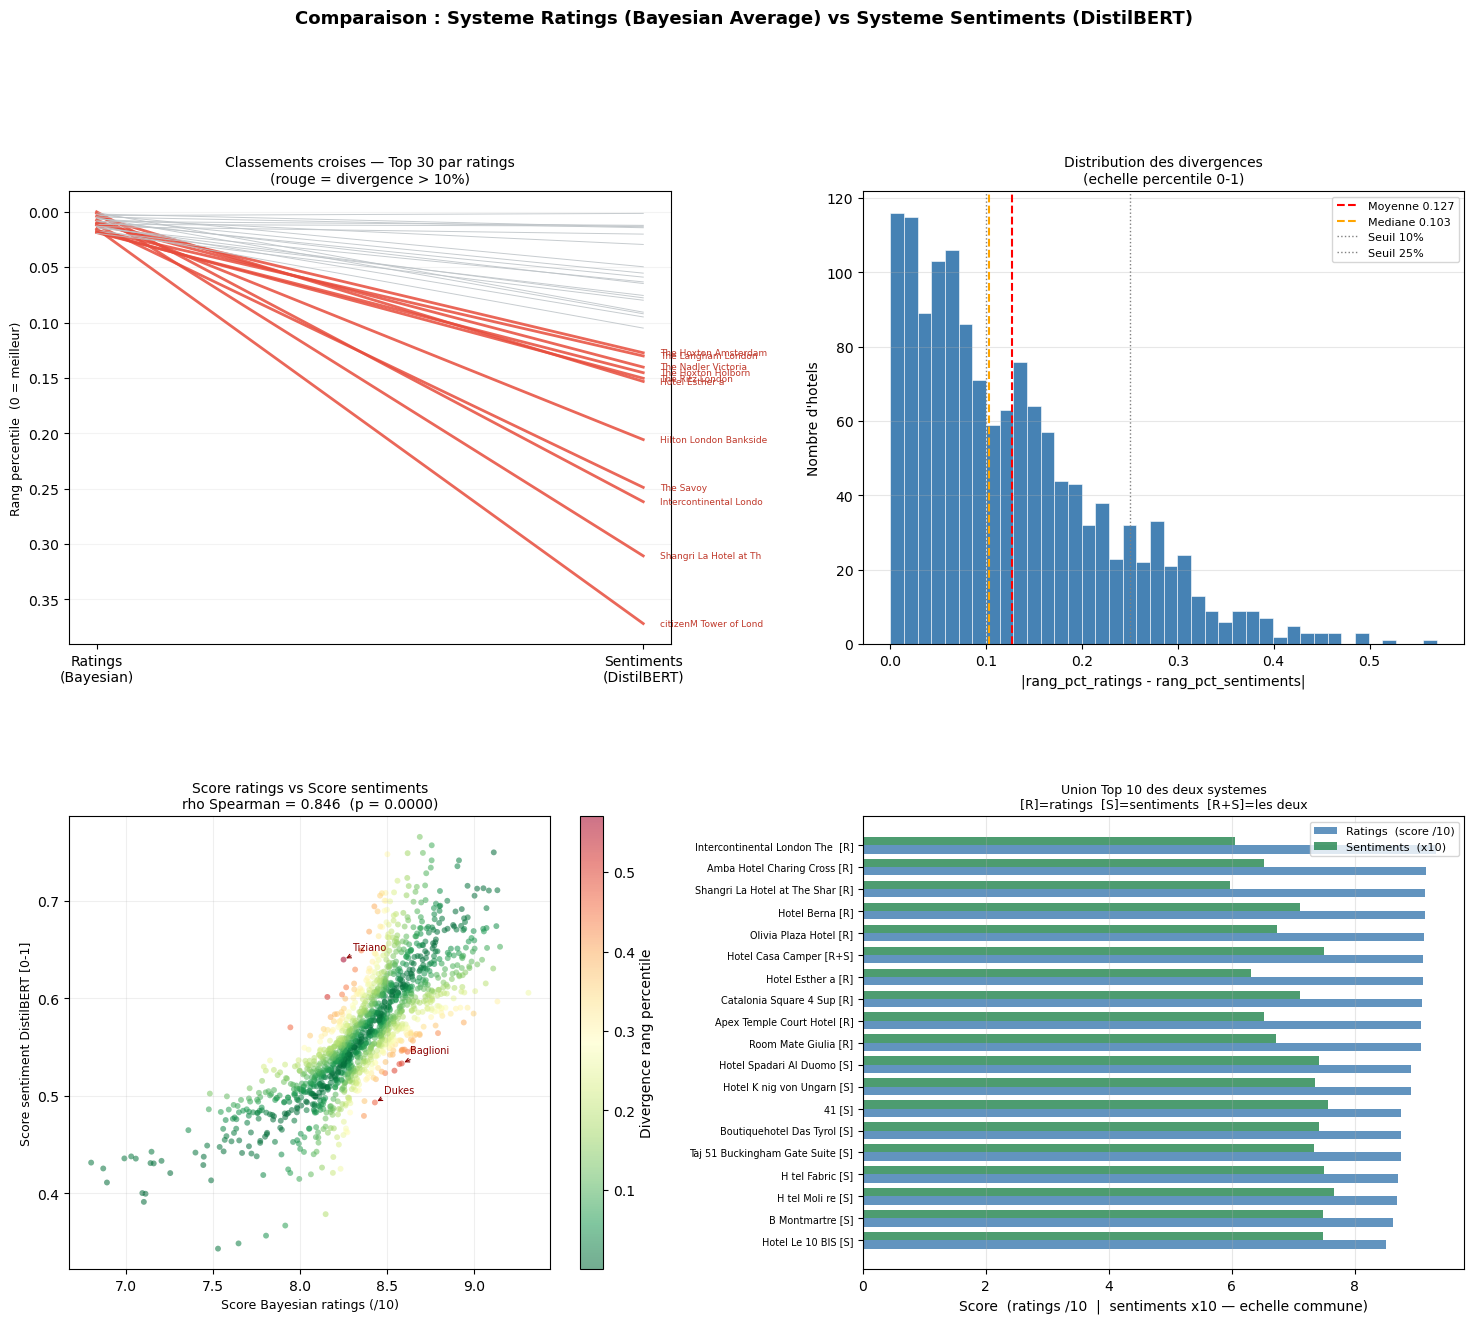

Sauvegarde -> results/visualizations/comparaison_classements.png


In [8]:
fig = plt.figure(figsize=(18, 14))
gs  = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.32)

# ── Graphique 1 : Bump chart Top 30 ──────────────────────────────────────
ax1  = fig.add_subplot(gs[0, 0])
top30 = comparaison.nsmallest(30, 'rang_ratings').copy()
seuil_bump = 0.10

for _, row in top30.iterrows():
    div = row['diff_rang_pct']
    c   = '#e74c3c' if div > seuil_bump else '#bdc3c7'
    lw  = 2.0       if div > seuil_bump else 0.7
    ax1.plot([1, 2], [row['rang_pct_ratings'], row['rang_pct_sentiments']],
             color=c, linewidth=lw, alpha=0.85)
    if div > seuil_bump:
        ax1.text(2.03, row['rang_pct_sentiments'],
                 row['Hotel_Name'][:22], fontsize=6.5, va='center', color='#c0392b')

ax1.set_xticks([1, 2])
ax1.set_xticklabels(['Ratings\n(Bayesian)', 'Sentiments\n(DistilBERT)'], fontsize=10)
ax1.invert_yaxis()
ax1.set_ylabel('Rang percentile  (0 = meilleur)', fontsize=9)
ax1.set_title('Classements croises — Top 30 par ratings\n'
              '(rouge = divergence > 10%)', fontsize=10)
ax1.grid(axis='y', alpha=0.15)

# ── Graphique 2 : Distribution des divergences ────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
moy = comparaison['diff_rang_pct'].mean()
med = comparaison['diff_rang_pct'].median()
ax2.hist(comparaison['diff_rang_pct'], bins=40,
         color='steelblue', edgecolor='white', linewidth=0.4)
ax2.axvline(moy, color='red',    linestyle='--', linewidth=1.5, label=f'Moyenne {moy:.3f}')
ax2.axvline(med, color='orange', linestyle='--', linewidth=1.5, label=f'Mediane {med:.3f}')
ax2.axvline(0.10, color='gray',  linestyle=':',  linewidth=1.0, label='Seuil 10%')
ax2.axvline(0.25, color='gray',  linestyle=':',  linewidth=1.0, label='Seuil 25%')
ax2.set_xlabel('|rang_pct_ratings - rang_pct_sentiments|')
ax2.set_ylabel("Nombre d'hotels")
ax2.set_title('Distribution des divergences\n(echelle percentile 0-1)', fontsize=10)
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.3)

# ── Graphique 3 : Scatter score_bayes vs sentiment_score ─────────────────
ax3 = fig.add_subplot(gs[1, 0])
sc  = ax3.scatter(
    comparaison['score_bayes'],
    comparaison['sentiment_score'],
    c=comparaison['diff_rang_pct'], cmap='RdYlGn_r',
    alpha=0.55, s=18, edgecolors='none'
)
plt.colorbar(sc, ax=ax3, label='Divergence rang percentile')

# Annoter les 3 cas documentés dans le rapport
cas = {'Dukes Hotel': 'Dukes',
       'Baglioni Hotel London': 'Baglioni',
       'Hotel Tiziano Park': 'Tiziano'}
for nom, label in cas.items():
    row = comparaison[comparaison['Hotel_Name'].str.contains(nom, case=False, na=False, regex=False)]
    if len(row):
        r = row.iloc[0]
        ax3.annotate(label,
                     xy=(r['score_bayes'], r['sentiment_score']),
                     xytext=(r['score_bayes']+0.05, r['sentiment_score']+0.01),
                     fontsize=7, color='darkred',
                     arrowprops=dict(arrowstyle='->', color='darkred', lw=0.8))

ax3.set_xlabel('Score Bayesian ratings (/10)', fontsize=9)
ax3.set_ylabel('Score sentiment DistilBERT [0-1]', fontsize=9)
ax3.set_title(f'Score ratings vs Score sentiments\n'
              f'rho Spearman = {corr:.3f}  (p = {pval:.4f})', fontsize=10)
ax3.grid(alpha=0.2)

# ── Graphique 4 : Union Top 10 (CORRIGE) ─────────────────────────────────
# Version corrigee : on affiche l'UNION des deux top 10,
# chaque ligne = 1 hotel avec ses DEUX scores cote a cote.
ax4 = fig.add_subplot(gs[1, 1])

top10_r_names = set(comparaison.nsmallest(10, 'rang_ratings')['Hotel_Name'])
top10_s_names = set(comparaison.nsmallest(10, 'rang_sentiments')['Hotel_Name'])
union_names   = top10_r_names | top10_s_names

union_df = (comparaison[comparaison['Hotel_Name'].isin(union_names)]
            .sort_values('rang_ratings').reset_index(drop=True))

y  = np.arange(len(union_df))
w  = 0.38

ax4.barh(y + w/2, union_df['score_bayes'].values,
         w, label='Ratings  (score /10)', color='steelblue', alpha=0.85)
ax4.barh(y - w/2, union_df['sentiment_score'].values * 10,
         w, label='Sentiments  (x10)', color='seagreen', alpha=0.85)

labels_y = []
for _, row in union_df.iterrows():
    tag = ''
    if row['Hotel_Name'] in top10_r_names and row['Hotel_Name'] in top10_s_names:
        tag = ' [R+S]'
    elif row['Hotel_Name'] in top10_r_names:
        tag = ' [R]'
    else:
        tag = ' [S]'
    labels_y.append(row['Hotel_Name'][:28] + tag)

ax4.set_yticks(y)
ax4.set_yticklabels(labels_y, fontsize=7)
ax4.invert_yaxis()
ax4.set_xlabel('Score  (ratings /10  |  sentiments x10 — echelle commune)')
ax4.set_title('Union Top 10 des deux systemes\n'
              '[R]=ratings  [S]=sentiments  [R+S]=les deux', fontsize=9)
ax4.legend(fontsize=8)
ax4.grid(axis='x', alpha=0.3)

plt.suptitle(
    'Comparaison : Systeme Ratings (Bayesian Average) vs Systeme Sentiments (DistilBERT)',
    fontsize=13, fontweight='bold', y=1.01)

plt.savefig('../results/visualizations/comparaison_classements.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegarde -> results/visualizations/comparaison_classements.png')

## 9. Métriques — résumé pour le rapport

In [9]:
print('=' * 64)
print('  TABLEAU DE BORD — COMPARAISON DES DEUX SYSTEMES')
print('=' * 64)
print(f'  Hotels analyses                  : {len(comparaison):,}')
print(f'  Correlation Spearman rho         : {corr:.4f}')
print(f'  P-value                          : {pval:.6f}')
print(f'  Divergence moyenne               : {comparaison["diff_rang_pct"].mean():.3f}')
print(f'  Divergence mediane               : {comparaison["diff_rang_pct"].median():.3f}')
print(f'  Divergence max                   : {comparaison["diff_rang_pct"].max():.3f}')
print(f'  Hotels convergents (ecart < 10%) : {(comparaison["diff_rang_pct"] < 0.10).sum()}')
print(f'  Hotels divergents  (ecart > 25%) : {(comparaison["diff_rang_pct"] > 0.25).sum()}')
print()
print('  TOP 5 — Systeme Ratings')
print(comparaison.nsmallest(5, 'rang_ratings')
      [['Hotel_Name','rang_ratings','score_bayes','rang_sentiments','sentiment_score']]
      .round(3).to_string(index=False))
print()
print('  TOP 5 — Systeme Sentiments')
print(comparaison.nsmallest(5, 'rang_sentiments')
      [['Hotel_Name','rang_sentiments','sentiment_score','rang_ratings','score_bayes']]
      .round(3).to_string(index=False))
print('=' * 64)

  TABLEAU DE BORD — COMPARAISON DES DEUX SYSTEMES
  Hotels analyses                  : 1,391
  Correlation Spearman rho         : 0.8459
  P-value                          : 0.000000
  Divergence moyenne               : 0.127
  Divergence mediane               : 0.103
  Divergence max                   : 0.570
  Hotels convergents (ecart < 10%) : 686
  Hotels divergents  (ecart > 25%) : 190

  TOP 5 — Systeme Ratings
                          Hotel_Name  rang_ratings  score_bayes  rang_sentiments  sentiment_score
      Intercontinental London The O2             1        9.315              365            0.606
            Amba Hotel Charing Cross             2        9.152              127            0.653
Shangri La Hotel at The Shard London             3        9.137              433            0.597
                         Hotel Berna             4        9.136               20            0.711
                  Olivia Plaza Hotel             5        9.130               70         

## 10. Sauvegarde

In [10]:
comparaison.to_csv('../results/comparaison_systemes.csv', index=False)

metrics = pd.DataFrame([{
    'nb_hotels'          : len(comparaison),
    'spearman_rho'       : round(corr, 4),
    'spearman_pval'      : round(pval, 6),
    'div_mean'           : round(comparaison['diff_rang_pct'].mean(), 4),
    'div_median'         : round(comparaison['diff_rang_pct'].median(), 4),
    'div_max'            : round(comparaison['diff_rang_pct'].max(), 4),
    'n_convergent_10pct' : int((comparaison['diff_rang_pct'] < 0.10).sum()),
    'n_divergent_25pct'  : int((comparaison['diff_rang_pct'] > 0.25).sum()),
}])
metrics.to_csv('../results/metrics_report.csv', index=False)

print('Fichiers sauvegardes :')
print('  -> results/comparaison_systemes.csv')
print('  -> results/metrics_report.csv')
print('  -> results/visualizations/comparaison_classements.png')
print(f'\nColonnes comparaison_systemes.csv : {comparaison.columns.tolist()}')

Fichiers sauvegardes :
  -> results/comparaison_systemes.csv
  -> results/metrics_report.csv
  -> results/visualizations/comparaison_classements.png

Colonnes comparaison_systemes.csv : ['Hotel_Name', 'rang_ratings', 'rang_pct_ratings', 'score_bayes', 'nb_avis', 'rang_sentiments', 'rang_pct_sentiments', 'sentiment_score', 'n_snippets', 'pct_pred_positive', 'avg_score', 'diff_rang_pct', 'diff_rang_abs', 'sens_divergence']


## 11. Conclusion — Discussion pour le rapport

### Interprétation de la corrélation

| ρ | Interprétation | Conclusion |
|---|---|---|
| > 0.8 | Forte convergence | Sentiments redondants avec les notes |
| 0.5 – 0.8 | Corrélation modérée | Les deux signaux sont complémentaires → système hybride justifié |
| < 0.5 | Faible corrélation | Le texte est plus informatif que la note |

### Pourquoi la divergence est attendue et souhaitable

| Cause | Exemple concret |
|-------|----------------|
| **Biais de notation** | Client donne 9.6 et écrit *"broken window, bio weapon in fridge"* → Système 1 : positif / Système 2 : négatif |
| **Indépendance des labels** | DistilBERT est entraîné sur la structure du formulaire, pas sur les scores → les deux signaux sont réellement différents |
| **Intensité du sentiment** | P(Positive)=0.97 ≠ P(Positive)=0.53, alors que les deux seraient comptés comme "Positive" en binaire |
| **Plage bornée** | Sentiment score ∈ [0.34, 0.77] car chaque client remplit les deux champs — c'est structurel, pas une limite du modèle |

### Valeur ajoutée du projet

La comparaison montre que **les deux systèmes capturent des signaux distincts**.  
Un système hybride qui combine les deux scores serait plus robuste qu'un système unique,  
car il détecterait les cas où la note masque une insatisfaction textuelle (Dukes Hotel, Baglioni…)
ou au contraire récompense des hôtels peu notés mais textuellement bien perçus.
